# Faulty robots — how does the robot network perform?

**Question:** the session 1 network (M1, and M2 fine-tuned on rollouts) learned a *healthy* simulated robot.
How well does it simulate a **faulty** robot?

1. **Wheel fault:** one wheel delivers less speed than commanded (weak motor) or none at all.
2. **Banana fault:** when the robot moves sideways it also turns, so a straight sideways command traces a curve (a "banana").

We also check whether the **same kind of network can learn the faulty robot** when trained on its data, and how much data that takes.

Contents: 1. fault models · 2. data and fault analysis · 3. healthy network on faulty robots · 4. networks trained on faulty robots · 5. conclusions.

<details><summary>Reproduce</summary>

```sh
cd simulator && cargo build --release -p ssl-sim-datagen && cd ../nn_sim
python -m nn_sim.fault_study --data --train --eval    # needs the session 1 data and checkpoints
```
</details>

In [1]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from nn_sim import data, faults, reference as ref, rollout
from nn_sim.fault_study import load, VARIANTS
from nn_sim.train import load_model, DEVICE

pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
                     "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})
# Colors: fault kind = hue (wheel blue, banana orange), severity = lightness of that hue.
KIND = {"wheel": "#2a78d6", "banana": "#eb6834"}
SEV = {"wheel_0.75": "#86b4ea", "wheel_0.50": "#2a78d6", "wheel_0.00": "#154a8c",
       "banana_0.25": "#f4a988", "banana_0.50": "#eb6834", "banana_1.00": "#9c3a12"}
TRUTH, HEALTHY, NET, FIXED = "#3a3a38", "#a9a8a2", "#1baf7a", "#6250d6"
FAULTS = list(faults.FAULTS)
RES = json.load(open("results/faults.json")); CUR = np.load("results/faults_curves.npz")
M1 = load_model("M1_s0")

def simulate(M, us, s0=None):
    s0 = np.zeros(6) if s0 is None else s0
    return ref.rollout(s0, faults.apply(np.asarray(us, float), M))

def net_rollout(model, us, s0=None):
    s0 = np.zeros(6) if s0 is None else s0
    with torch.no_grad():
        return rollout.rollout(model, torch.as_tensor(s0[None], device=DEVICE),
                               torch.as_tensor(np.asarray(us, float)[None], device=DEVICE))[0].cpu().numpy()

def script(*parts):
    # parts: (seconds, vt, vn, w)
    return np.concatenate([np.tile([vt, vn, w], (int(round(sec * 60)), 1)) for sec, vt, vn, w in parts])

SCRIPTS = {"forward 1.5 m/s, 2 s": script((2, 1.5, 0, 0)),
           "sideways (left) 1 m/s, 2 s": script((2, 0, 1.0, 0)),
           "square: fwd, left, back, right (1 s each, 1 m/s)": script((1, 1, 0, 0), (1, 0, 1, 0), (1, -1, 0, 0), (1, 0, -1, 0))}

## 1. Fault models

The simulator has no wheels: a healthy robot tracks the commanded body velocity $u = (v_t, v_n, \omega)$ within its
acceleration and speed limits. We model a faulty robot as one that **executes a distorted command** $M u$ instead of $u$.
The simulator's dynamics (limits, integration) then act on $M u$ exactly as before. Logs record the command *sent*, $u$,
as a log of a real faulty robot would. The network only ever sees $u$ and the resulting motion.

**Wheel fault.** Four omni wheels at angles $\alpha = (60°, 135°, 225°, 300°)$ (front-left, back-left, back-right, front-right),
at $L = 0.08$ m from the center. Rim speeds are $w = J u$ with $J_i = (-\sin\alpha_i,\ \cos\alpha_i,\ L)$.
The faulty wheel delivers only a fraction $k$ of its speed. With all wheels slipping equally, the body motion is the least-squares
fit of the four wheel speeds:

$$M_{wheel} = J^{+}\,\mathrm{diag}(k_1, 1, 1, 1)\,J \qquad (k_1 = 1 \Rightarrow M = I)$$

Studied: front-left wheel at **75%, 50% and 0%** (0% = wheel delivers nothing, e.g. dead or locked motor).

**Banana fault.** Strafing makes the robot turn: $\omega_{actual} = \omega_{cmd} + \kappa\, v_n$. A pure sideways command then follows an
arc of radius $v_n/\omega = 1/\kappa$. Studied: $\kappa$ = **0.25, 0.5 and 1.0** rad/s per m/s (arc radius 4 m, 2 m, 1 m).

Severity scale used in the plots: wheel = $1-k$ (0.25, 0.5, 1.0); banana = $\kappa$ (0.25, 0.5, 1.0). Healthy = 0.

In [2]:
rows = {}
for name, (kind, sev, M) in faults.FAULTS.items():
    r = {"kind": kind, "severity": sev}
    r.update({f"M[{i},{j}]": M[i, j] for i in range(3) for j in range(3)})
    f = M @ [1.5, 0, 0]; s = M @ [0, 1, 0]
    r["fwd 1.5 m/s → (vt, vn, ω)"] = f"({f[0]:.2f}, {f[1]:.2f}, {f[2]:.2f})"
    r["left 1 m/s → (vt, vn, ω)"] = f"({s[0]:.2f}, {s[1]:.2f}, {s[2]:.2f})"
    rows[name] = r
display(pd.DataFrame(rows).T.style.format(precision=3).set_caption("Fault matrices: what the robot executes for a command"))

,kind,severity,"M[0,0]","M[0,1]","M[0,2]","M[1,0]","M[1,1]","M[1,2]","M[2,0]","M[2,1]","M[2,2]","fwd 1.5 m/s → (vt, vn, ω)","left 1 m/s → (vt, vn, ω)"
wheel_0.75,wheel,0.250,0.925,0.043,0.007,0.090,0.948,-0.008,0.793,-0.458,0.927,"(1.39, 0.13, 1.19)","(0.04, 0.95, -0.46)"
wheel_0.50,wheel,0.500,0.850,0.087,0.014,0.179,0.896,-0.017,1.585,-0.915,0.854,"(1.28, 0.27, 2.38)","(0.09, 0.90, -0.92)"
wheel_0.00,wheel,1.000,0.700,0.173,0.028,0.359,0.793,-0.033,3.171,-1.831,0.707,"(1.05, 0.54, 4.76)","(0.17, 0.79, -1.83)"
banana_0.25,banana,0.250,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.250,1.000,"(1.50, 0.00, 0.00)","(0.00, 1.00, 0.25)"
banana_0.50,banana,0.500,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.500,1.000,"(1.50, 0.00, 0.00)","(0.00, 1.00, 0.50)"
banana_1.00,banana,1.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,1.000,"(1.50, 0.00, 0.00)","(0.00, 1.00, 1.00)"


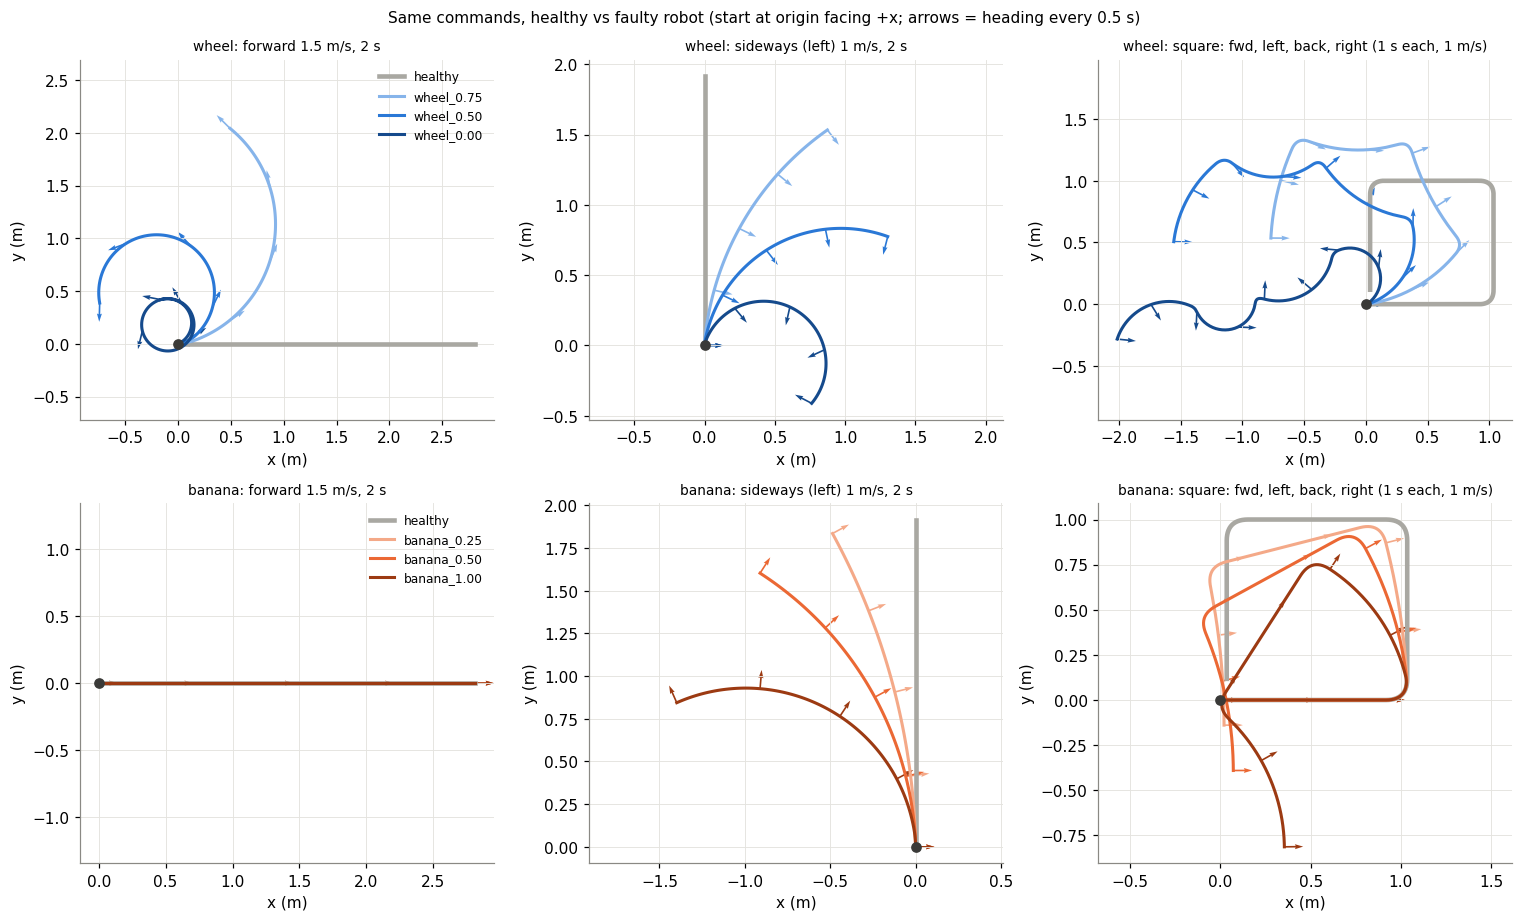

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for r, kind in enumerate(["wheel", "banana"]):
    for c, (title, us) in enumerate(SCRIPTS.items()):
        ax = axes[r, c]
        tr = simulate(np.eye(3), us); ax.plot(tr[:, 0], tr[:, 1], color=HEALTHY, lw=3, label="healthy")
        for name in [n for n in FAULTS if n.startswith(kind)]:
            tr = simulate(faults.FAULTS[name][2], us)
            ax.plot(tr[:, 0], tr[:, 1], color=SEV[name], label=name)
            k = np.arange(0, len(tr), 30)
            ax.quiver(tr[k, 0], tr[k, 1], np.cos(tr[k, 2]), np.sin(tr[k, 2]), color=SEV[name], scale=22, width=0.004)
        ax.plot(0, 0, "o", color=TRUTH, ms=6); ax.set_aspect("equal", "datalim")
        ax.set_title(f"{kind}: {title}", fontsize=9); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    axes[r, 0].legend(fontsize=8, loc="best")
fig.suptitle("Same commands, healthy vs faulty robot (start at origin facing +x; arrows = heading every 0.5 s)", fontsize=10)
fig.tight_layout()

* **Wheel fault:** the weak wheel makes the robot **spin** and slip sideways for any motion. Driving forward at 1.5 m/s with a 50% wheel
  adds ~2.4 rad/s of rotation, so the robot loops instead of going straight. With a dead wheel it spins even faster.
* **Banana fault:** forward motion is unaffected; **sideways motion curves**, and the robot also rotates while doing it.

## 2. Data and fault analysis

Same generator and settings as session 1, with the fault applied. Each fault has a **test_mix** set (seed 3) and a **test_wp** set (seed 4,
waypoint controller). Seeds are the same as the healthy test sets, so the mixed-signal commands are **identical**
to the healthy ones (paired comparison). The waypoint controller reacts to where the faulty robot actually is, so its commands differ.
`wheel_0.50` and `banana_0.50` also have train (2000 episodes) and val sets, used in section 4.

In [4]:
rows = []
for name in FAULTS:
    for split in ["test_mix", "test_wp"] + (["train", "val"] if name in faults.TRAINED else []):
        ds = load(name, split)
        rows.append({"fault": name, "split": split, "episodes": ds.n_episodes, "transitions": ds.n_episodes * ds.ticks})
t = data.transitions(load("wheel_0.00", "test_mix"))
pred = ref.step(t["s0"], faults.apply(t["u"], faults.FAULTS["wheel_0.00"][2]))
print(f"check: simulator response to M·u reproduced to {np.abs(pred - t['s1'])[:, [0, 1, 3, 4, 5]].max():.1e} (wheel_0.00; all faults verified at generation)")
display(pd.DataFrame(rows).pivot(index="fault", columns="split", values="transitions").fillna("–"))

check: simulator response to M·u reproduced to 2.1e-14 (wheel_0.00; all faults verified at generation)


split,test_mix,test_wp,train,val
fault,,,,
banana_0.25,120000.0,120000.0,–,–
banana_0.50,120000.0,120000.0,1200000.0,120000.0
banana_1.00,120000.0,120000.0,–,–
wheel_0.00,120000.0,120000.0,–,–
wheel_0.50,120000.0,120000.0,1200000.0,120000.0
wheel_0.75,120000.0,120000.0,–,–


### 2.1 Fault fingerprint: what the healthy network gets wrong

The healthy network's one-step **residual** (true Δ − predicted Δ) is ~0 on a healthy robot. On a faulty robot the residual shows the
fault's signature. Below: the residual in angular velocity change, Δω, against the commanded forward and sideways speed.

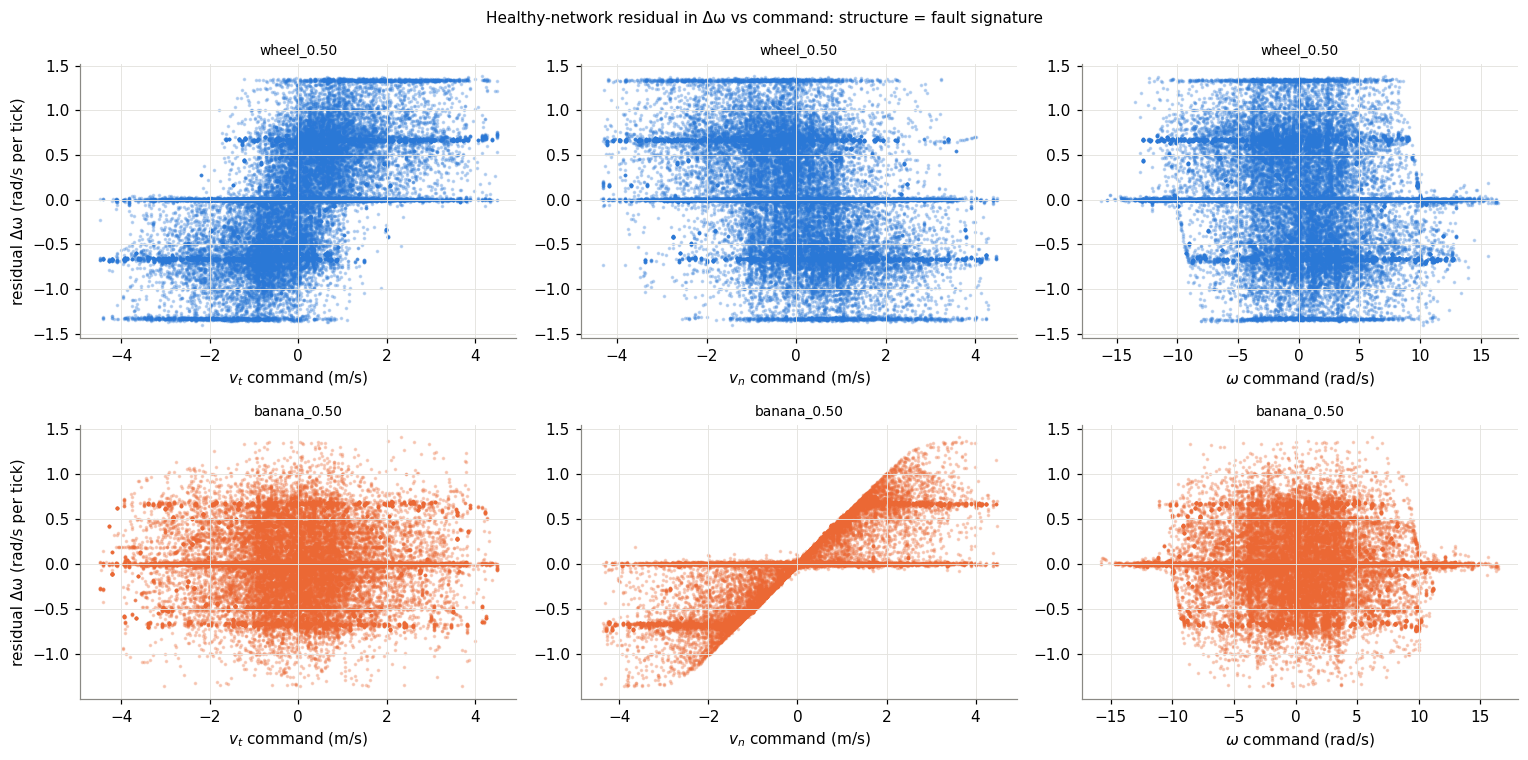

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
rng = np.random.default_rng(0)
for r, name in enumerate(["wheel_0.50", "banana_0.50"]):
    t = data.transitions(load(name, "test_mix"))
    with torch.no_grad():
        p = M1(torch.as_tensor(t["z"], device=DEVICE)).cpu().numpy()
    res = t["d"] - p
    i = rng.choice(len(res), 40000, replace=False)
    for c, (col, lab) in enumerate([(3, "$v_t$ command (m/s)"), (4, "$v_n$ command (m/s)"), (5, "$\\omega$ command (rad/s)")]):
        ax = axes[r, c]
        ax.scatter(t["z"][i, col], res[i, 2], s=2, alpha=0.25, color=SEV[name], rasterized=True)
        ax.set_xlabel(lab); ax.set_ylabel("residual Δω (rad/s per tick)" if c == 0 else "")
        ax.set_title(name, fontsize=9)
fig.suptitle("Healthy-network residual in Δω vs command: structure = fault signature", fontsize=10); fig.tight_layout()

* **wheel_0.50:** the Δω residual depends on **both** $v_t$ and $v_n$, since any translation makes the robot turn. That matches the third
  row of $M_{wheel}$ ($\omega$ gets 1.59·$v_t$ − 0.92·$v_n$).
* **banana_0.50:** the residual depends **only** on $v_n$. Forward commands look perfectly healthy.
* In both, the residual is bounded by ±2$\alpha_{max}\Delta t$ = ±1.33 rad/s per tick. The turn caused by the fault is still limited by the
  robot's angular acceleration, and in the worst case the network predicts full angular acceleration one way while the robot does it the other way.
  The horizontal bands at 0, ±0.67 and ±1.33 are those saturated cases.

### 2.2 Identifying the fault from the data (no network)

When the robot has settled (velocity no longer changing) and the command is within limits, the executed body velocity
equals $M u$. A least-squares fit on those samples estimates $\hat M$, the fault itself.

In [6]:
def identify(ds):
    ep = ds.episodes()
    s, u = data.states(ep), data.commands(ep)
    s0, s1, u0 = s[:, :-1].reshape(-1, 6), s[:, 1:].reshape(-1, 6), u[:, :-1].reshape(-1, 3)
    b0, b1 = data.features(s0, u0)[:, :3], data.features(s1, u0)[:, :3]  # (u_b, v_b, ω), each in its own robot frame
    settled = np.abs(b1 - b0).max(1) < 1e-9                    # constant body velocity: the robot executes M·u exactly
    speed = np.hypot(b1[:, 0], b1[:, 1])
    unclipped = (speed < 3.49) & (np.abs(b1[:, 2]) < 9.99) & (speed * np.abs(b1[:, 2]) < 5.9)  # no limit active
    m = settled & unclipped
    Mhat = np.linalg.lstsq(u0[m], b1[m], rcond=None)[0].T
    return Mhat, m.sum()

rows = {}
for name in ["wheel_0.50", "banana_0.50", "wheel_0.00", "banana_1.00"]:
    split = "train" if name in faults.TRAINED else "test_mix"
    Mhat, n = identify(load(name, split))
    M = faults.FAULTS[name][2]
    rows[name] = {"settled samples": n, "max |M̂ − M|": np.abs(Mhat - M).max(), "M̂ (rounded)": np.array2string(Mhat, precision=2, suppress_small=True)}
display(pd.DataFrame(rows).T)

,settled samples,max |M̂ − M|,M̂ (rounded)
wheel_0.50,160894,0.0,[[ 0.85 0.09 0.01]\n [ 0.18 0.9 -0.02]\n [...
banana_0.50,145137,0.0001,[[ 1. 0. 0. ]\n [-0. 1. -0. ]\n [ 0. ...
wheel_0.00,15658,0.0001,[[ 0.7 0.17 0.03]\n [ 0.36 0.79 -0.03]\n [...
banana_1.00,13510,0.0002,[[ 1. -0. -0.]\n [-0. 1. 0.]\n [ 0. 1. 1.]]


The fault matrix is **recovered from the logs** (error well below 1%). The fault is fully identifiable from ordinary driving data,
which makes "fault = M" a useful compact description of a faulty robot.

## 3. The healthy network on faulty robots

The session 1 networks (M1, M2), unchanged, are evaluated on every fault, using the same metrics as session 1
(one-step error, open-loop rollout from 1200 start points per set).

In [7]:
def row(m, name, split):
    r = RES["healthy_models"][m][name][split]
    return {"model": m, "fault": name, "set": split, "one-step NMSE": r["one_step"]["nmse"],
            "pos 0.1 s (mm)": r["rollout"]["0.1s"]["median"][0] * 1e3, "pos 1 s (mm)": r["rollout"]["1.0s"]["median"][0] * 1e3,
            "pos 5 s (mm)": r["rollout"]["5.0s"]["median"][0] * 1e3, "pos 5 s p95 (mm)": r["rollout"]["5.0s"]["p95"][0] * 1e3,
            "heading 1 s (°)": np.degrees(r["rollout"]["1.0s"]["median"][1]), "heading 5 s (°)": np.degrees(r["rollout"]["5.0s"]["median"][1])}

tab = pd.DataFrame([row(m, n, s) for m in ["M1", "M2"] for n in ["healthy"] + FAULTS for s in ["test_mix", "test_wp"]]).set_index(["model", "fault", "set"])
display(tab.loc["M1"].style.format("{:.3g}").set_caption("M1 (trained on the healthy robot), median errors"))
pos1 = tab.loc["M1"]["pos 1 s (mm)"].unstack()
ratio = pos1 / pos1.loc["healthy"]
display(ratio.style.format("{:.0f}×").set_caption("Position error at 1 s relative to the healthy robot"))

set,test_mix,test_wp
fault,,
banana_0.25,8×,12×
banana_0.50,16×,22×
banana_1.00,32×,36×
healthy,1×,1×
wheel_0.00,113×,78×
wheel_0.50,66×,109×
wheel_0.75,34×,70×


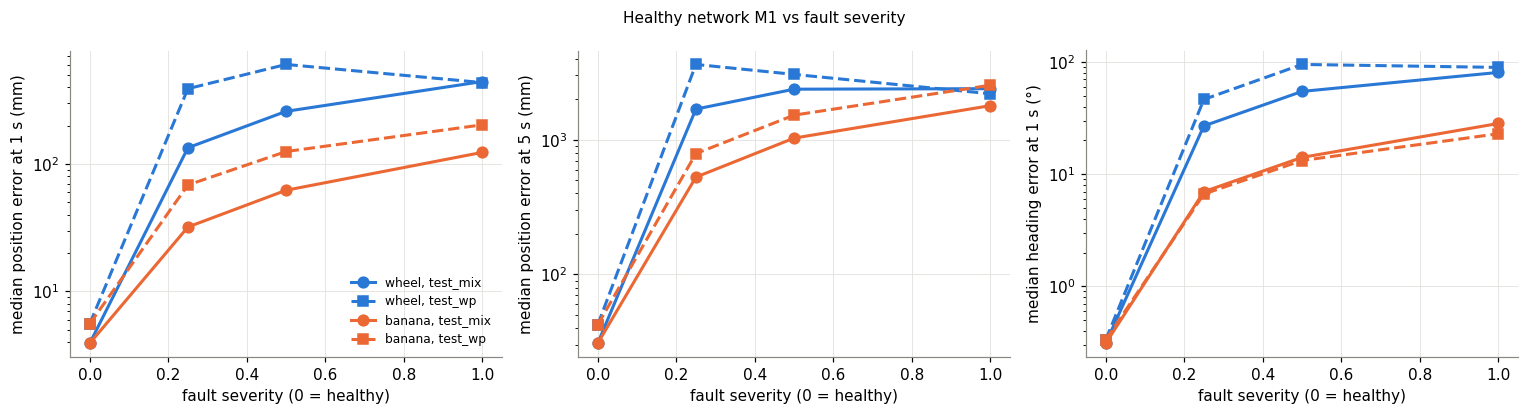

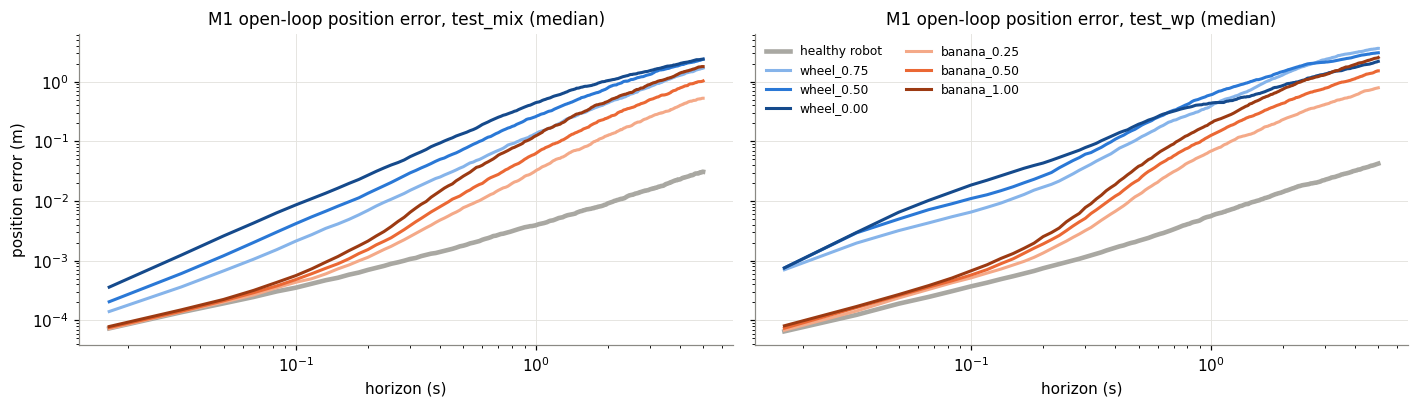

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for kind in ["wheel", "banana"]:
    names = ["healthy"] + [n for n in FAULTS if n.startswith(kind)]
    sev = [0.0] + [faults.FAULTS[n][1] for n in names[1:]]
    for split, ls, mk in [("test_mix", "-", "o"), ("test_wp", "--", "s")]:
        for ax, key, scale in [(axes[0], "1.0s", 1e3), (axes[1], "5.0s", 1e3)]:
            ax.plot(sev, [RES["healthy_models"]["M1"][n][split]["rollout"][key]["median"][0] * scale for n in names],
                    ls=ls, marker=mk, ms=7, color=KIND[kind], label=f"{kind}, {split}")
        axes[2].plot(sev, [np.degrees(RES["healthy_models"]["M1"][n][split]["rollout"]["1.0s"]["median"][1]) for n in names],
                     ls=ls, marker=mk, ms=7, color=KIND[kind], label=f"{kind}, {split}")
axes[0].set_ylabel("median position error at 1 s (mm)"); axes[1].set_ylabel("median position error at 5 s (mm)")
axes[2].set_ylabel("median heading error at 1 s (°)")
for ax in axes: ax.set_xlabel("fault severity (0 = healthy)"); ax.set_yscale("log")
axes[0].legend(fontsize=8); fig.suptitle("Healthy network M1 vs fault severity", fontsize=10); fig.tight_layout()

t = np.arange(301) * data.DT
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, split in zip(axes, ["test_mix", "test_wp"]):
    ax.loglog(t[1:], CUR[f"M1_healthy_{split}"][1:, 0], color=HEALTHY, lw=3, label="healthy robot")
    for name in FAULTS:
        ax.loglog(t[1:], CUR[f"M1_{name}_{split}"][1:, 0], color=SEV[name], label=name)
    ax.set_title(f"M1 open-loop position error, {split} (median)"); ax.set_xlabel("horizon (s)")
axes[0].set_ylabel("position error (m)"); axes[1].legend(fontsize=8, ncol=2); fig.tight_layout()

### 3.1 What the failure looks like

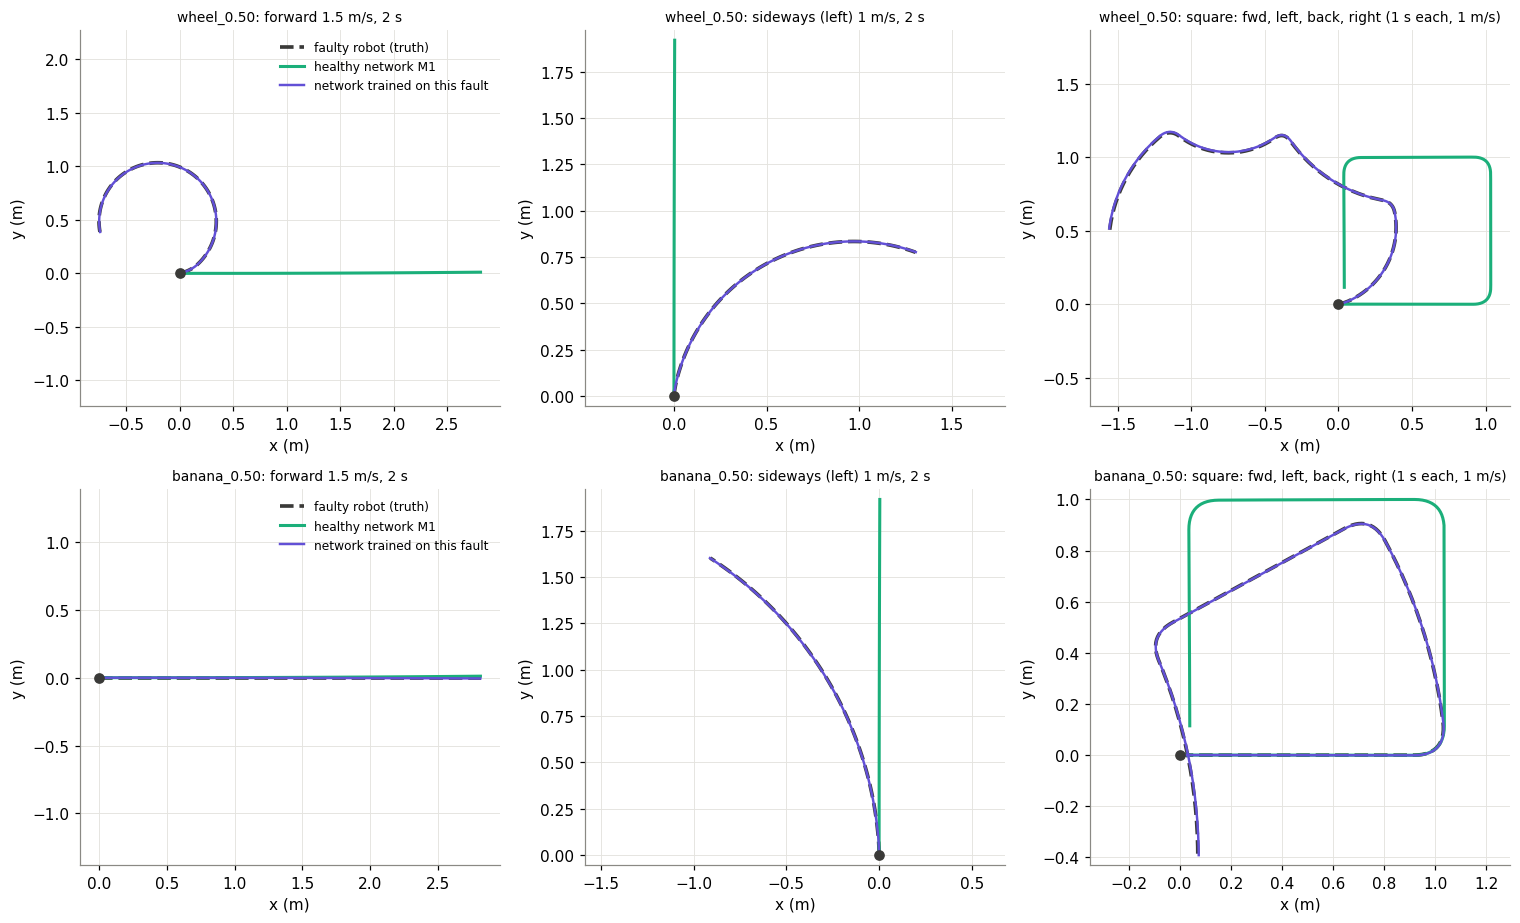

In [9]:
fixed = {n: load_model(f"fault_{n}_scratch_100pct") for n in faults.TRAINED}
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for r, name in enumerate(faults.TRAINED):
    M = faults.FAULTS[name][2]
    for c, (title, us) in enumerate(SCRIPTS.items()):
        ax = axes[r, c]
        tr = simulate(M, us); ax.plot(tr[:, 0], tr[:, 1], color=TRUTH, ls="--", lw=2.4, label=f"faulty robot (truth)")
        p = net_rollout(M1, us); ax.plot(p[:, 0], p[:, 1], color=NET, label="healthy network M1")
        p = net_rollout(fixed[name], us); ax.plot(p[:, 0], p[:, 1], color=FIXED, lw=1.6, label="network trained on this fault")
        ax.plot(0, 0, "o", color=TRUTH, ms=6); ax.set_aspect("equal", "datalim")
        ax.set_title(f"{name}: {title}", fontsize=9); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    axes[r, 0].legend(fontsize=8)
fig.tight_layout()

The healthy network predicts what a **healthy robot** would do: straight lines and clean squares. It has no way to know the
robot is faulty, because nothing in its input says so. A network trained on the faulty robot follows the true path.

### 3.2 Can the healthy network detect a fault?

Even though it simulates faulty robots badly, the healthy network can act as a **fault detector**. Over a 1 s window, compare
the mean one-step residual (standardized) with what is normal on a healthy robot. Threshold = 99th percentile on healthy val data
(1% false alarms by construction).

In [10]:
d_std = data.transitions(data.load("train"))["d"].std(0)
def window_scores(ds, model=M1, win=60):
    t = data.transitions(ds)
    with torch.no_grad():
        p = model(torch.as_tensor(t["z"], device=DEVICE)).cpu().numpy()
    r = (((t["d"] - p) / d_std) ** 2).mean(1).reshape(ds.n_episodes, ds.ticks)
    return r[:, : (ds.ticks // win) * win].reshape(ds.n_episodes, -1, win).mean(2).ravel()

thr = np.percentile(window_scores(data.load("val")), 99)
rows = {}
for name in ["healthy"] + FAULTS:
    rows[name] = {split: (window_scores(load(name, split)) > thr).mean() for split in ["test_mix", "test_wp"]}
display(pd.DataFrame(rows).T.style.format("{:.1%}").set_caption(f"Fraction of 1 s windows flagged as faulty (threshold {thr:.2e})"))

,test_mix,test_wp
healthy,1.4%,0.2%
wheel_0.75,98.1%,99.8%
wheel_0.50,98.6%,100.0%
wheel_0.00,98.9%,100.0%
banana_0.25,81.0%,80.8%
banana_0.50,88.9%,85.6%
banana_1.00,92.7%,88.2%


## 4. Networks trained on the faulty robot

For `wheel_0.50` and `banana_0.50`, the same network architecture as M1 is trained on the faulty robot's data in four ways:

| Variant | Data | Start | Steps |
|---|---|---|---|
| scratch_100pct | 2000 episodes (≈5.5 h of driving) | random | 12k |
| scratch_1pct | 20 episodes (≈3.3 min) | random | 12k |
| finetune_1pct | 20 episodes | healthy M1 | 3k |
| finetune_10pct | 200 episodes (≈33 min) | healthy M1 | 3k |

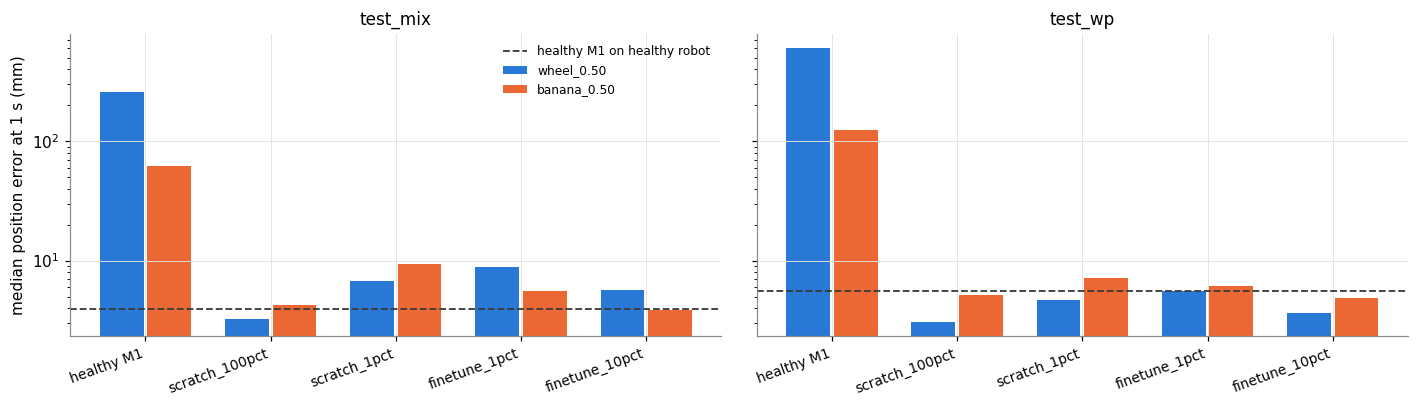

In [11]:
rows = []
for trained in faults.TRAINED:
    base = RES["healthy_models"]["M1"][trained]
    for split in ["test_mix", "test_wp"]:
        rows.append({"fault": trained, "model": "healthy M1 (no adaptation)", "set": split, "one-step NMSE": base[split]["one_step"]["nmse"],
                     "pos 1 s (mm)": base[split]["rollout"]["1.0s"]["median"][0] * 1e3, "pos 5 s (mm)": base[split]["rollout"]["5.0s"]["median"][0] * 1e3,
                     "train time (s)": np.nan})
        for variant, *_ in VARIANTS:
            v = RES["fault_models"][trained][variant]; r = v["tests"][trained][split]
            rows.append({"fault": trained, "model": variant, "set": split, "one-step NMSE": r["one_step"]["nmse"],
                         "pos 1 s (mm)": r["rollout"]["1.0s"]["median"][0] * 1e3, "pos 5 s (mm)": r["rollout"]["5.0s"]["median"][0] * 1e3,
                         "train time (s)": v["train_seconds"]})
    h = RES["healthy_models"]["M1"]["healthy"]
for split in ["test_mix", "test_wp"]:
    rows.append({"fault": "reference", "model": "healthy M1 on healthy robot", "set": split, "one-step NMSE": h[split]["one_step"]["nmse"],
                 "pos 1 s (mm)": h[split]["rollout"]["1.0s"]["median"][0] * 1e3, "pos 5 s (mm)": h[split]["rollout"]["5.0s"]["median"][0] * 1e3,
                 "train time (s)": np.nan})
adapt = pd.DataFrame(rows).set_index(["fault", "model", "set"])
display(adapt.style.format("{:.3g}", na_rep="–"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
labels = ["healthy M1"] + [v[0] for v in VARIANTS]
x = np.arange(len(labels)); w = 0.38
for ax, split in zip(axes, ["test_mix", "test_wp"]):
    for k, trained in enumerate(faults.TRAINED):
        vals = [adapt.loc[(trained, "healthy M1 (no adaptation)", split), "pos 1 s (mm)"]] + \
               [adapt.loc[(trained, v[0], split), "pos 1 s (mm)"] for v in VARIANTS]
        ax.bar(x + (k - 0.5) * w, vals, w * 0.92, color=KIND[faults.FAULTS[trained][0]], label=trained)
    ax.axhline(adapt.loc[("reference", "healthy M1 on healthy robot", split), "pos 1 s (mm)"], color=TRUTH, ls="--", lw=1.2,
               label="healthy M1 on healthy robot")
    ax.set_yscale("log"); ax.set_xticks(x, labels, rotation=20, ha="right", fontsize=9); ax.set_title(split)
axes[0].set_ylabel("median position error at 1 s (mm)"); axes[0].legend(fontsize=8); fig.tight_layout()

### 4.1 Does a model trained on one severity work on the others?

The fault-specific networks were trained at severity 0.5. Tested on the other severities of the same fault and on the healthy robot:

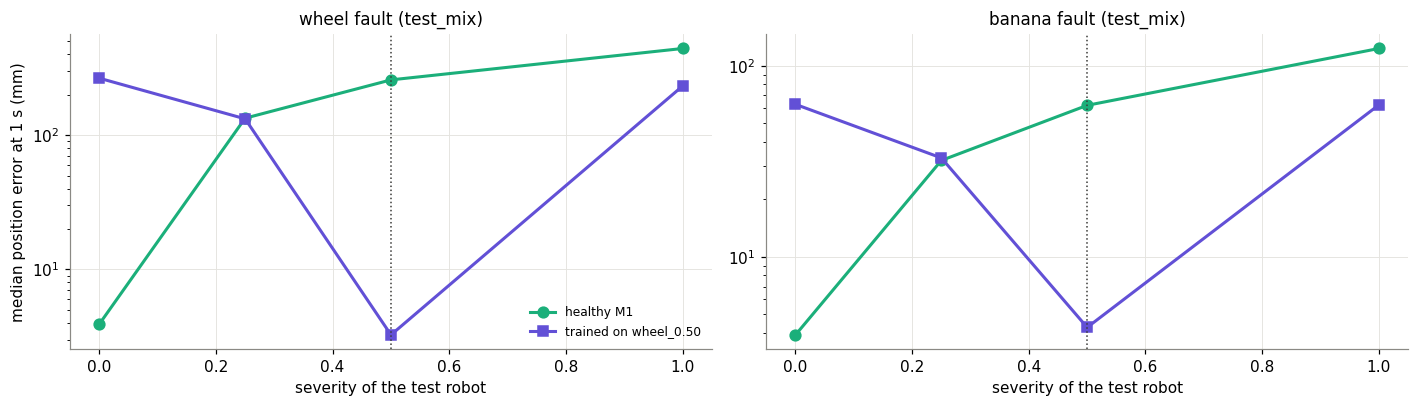

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, trained in zip(axes, faults.TRAINED):
    kind = faults.FAULTS[trained][0]
    names = ["healthy"] + [n for n in FAULTS if n.startswith(kind)]
    sev = [0.0] + [faults.FAULTS[n][1] for n in names[1:]]
    ax.plot(sev, [RES["healthy_models"]["M1"][n]["test_mix"]["rollout"]["1.0s"]["median"][0] * 1e3 for n in names],
            marker="o", ms=7, color=NET, label="healthy M1")
    ax.plot(sev, [RES["fault_models"][trained]["scratch_100pct"]["tests"][n]["test_mix"]["rollout"]["1.0s"]["median"][0] * 1e3 for n in names],
            marker="s", ms=7, color=FIXED, label=f"trained on {trained}")
    ax.axvline(faults.FAULTS[trained][1], color=TRUTH, ls=":", lw=1)
    ax.set_yscale("log"); ax.set_xlabel("severity of the test robot"); ax.set_title(f"{kind} fault (test_mix)")
axes[0].set_ylabel("median position error at 1 s (mm)"); axes[0].legend(fontsize=8); fig.tight_layout()

rows = []
for trained in faults.TRAINED:
    kind = faults.FAULTS[trained][0]
    for n in ["healthy"] + [x for x in FAULTS if x.startswith(kind)]:
        rows.append({"trained on": trained, "tested on": n,
                     **{f"{v[0]} 1 s (mm)": RES["fault_models"][trained][v[0]]["tests"][n]["test_mix"]["rollout"]["1.0s"]["median"][0] * 1e3 for v in VARIANTS}})
display(pd.DataFrame(rows).set_index(["trained on", "tested on"]).style.format("{:.3g}"))

## 5. Conclusions

### Summary

* **The healthy network does not simulate faulty robots.** It keeps predicting a healthy robot, so its error grows with fault severity:
  * **wheel fault:** 1 s position error **13–60 cm** (34–113× the healthy 4–6 mm). Heading is completely lost after ~1 s
    (median 5 s heading error ≈ 90°, i.e. no better than guessing).
  * **banana fault:** 1 s position error **3–20 cm** (8–36× healthy). Only sideways motion is affected, so forward driving is still predicted well.
  * M2 (trajectory-trained) is no better than M1 here: the problem is the wrong robot, not drift.
* **The same network learns a faulty robot perfectly well when trained on it:** 3–5 mm at 1 s, the same accuracy as for the healthy robot.
  A fault does not make the robot harder to learn; it only makes it a *different* robot.
* **Adaptation needs little data.** With 200 episodes (~33 min of driving), fine-tuning the healthy network for 3 s reaches healthy-level accuracy
  (3.7–5.6 mm). With 20 episodes (~3 min) it reaches 5.6–8.9 mm. Starting from the healthy network clearly helps for the banana fault
  (5.6 vs 9.4 mm with the same 20 episodes), but not for the wheel fault (8.9 vs 6.7 mm), whose behavior is far from healthy.
* **A network trained on one robot only works for that robot.** Trained at severity 0.5, it is as wrong as the healthy network on severity 0.25 or 1.0,
  and on the healthy robot. It does not interpolate between faults.
* **The healthy network is a good fault detector.** Its residual over 1 s windows flags **98–100%** of windows from wheel-faulty robots and
  **81–93%** from banana robots (banana windows without sideways motion look healthy), with 0.2–1.4% false alarms on healthy robots.
* **Faults are identifiable from ordinary logs:** a linear fit on settled samples recovers the fault matrix M to ~1e-4, without any network.

### Limitations

* The faults are **idealized linear maps** on the command: one fixed efficiency per wheel with equal slip on all wheels (least squares), and a constant
  banana coefficient. Real faults can be nonlinear (dead zones, speed-dependent friction), intermittent, or change over time.
* Wheel geometry (angles, 8 cm radius) is assumed, not measured on your robots. Only the front-left wheel was tested.
* As in session 1: perfect, noise-free state, no latency, no walls or ball.
* Fine-tuning and training from scratch used different numbers of steps (3k vs 12k), so the comparison at 1% data is not compute-matched.
* The waypoint controller reacts to the faulty robot (it is a closed loop), but the rollouts replay its recorded commands open loop, as in session 1.